# RQ1 Walkthrough: Chunking and Retrieval on One Sample Report

This notebook demonstrates, for a **single report**:

1. How each chunking strategy/size segments the text.
2. What the produced chunks look like.
3. How each retrieval method ranks chunks for one sample query.
4. How ranking changes between dense/sparse, fusion, and rerank.

In [3]:
# ------------------------------------------------------------
# 1) Imports and sample selection
# ------------------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt


import sys
from pathlib import Path
# Add project root so `rag` is importable when running from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from rag.config.settings import PipelineConfig
from rag.data.loaders import load_reports, load_golden_samples
from rag.chunking.strategies import build_chunks_for_config
from rag.indexing.embedder import EmbeddingService
from rag.indexing.qdrant_index import QdrantChunkIndex
from rag.retrieval.methods import Retriever

reports = load_reports()
samples = load_golden_samples()

SAMPLE_COMPANY = 'Shell'
SAMPLE_QUERY = next(s.question for s in samples if s.company == SAMPLE_COMPANY)

print('Sample company:', SAMPLE_COMPANY)
print('Sample query:', SAMPLE_QUERY)

Sample company: Shell
Sample query: How has the undertaking conducted its double materiality assessment, and which sustainability matters were identified as material from both an impact and a financial perspective?


In [4]:
# ------------------------------------------------------------
# 2) Generate chunk views for all strategies and sizes
# ------------------------------------------------------------
# This section builds chunks and records descriptive stats for one company.

records = []
all_chunks_by_cfg = {}
for strategy in ['fixed', 'structure_aware', 'semantic']:
    for size in [256, 512, 1024]:
        cfg = PipelineConfig(chunk_strategy=strategy, chunk_size=size, retrieval_method='hybrid_rrf')
        chunks, stats = build_chunks_for_config({SAMPLE_COMPANY: reports[SAMPLE_COMPANY]}, cfg)
        all_chunks_by_cfg[(strategy, size)] = chunks
        records.append({
            'chunk_strategy': strategy,
            'chunk_size': size,
            'total_chunks': stats.total_chunks,
            'mean_tokens': stats.mean_tokens,
            'std_tokens': stats.std_tokens,
            'min_tokens': stats.min_tokens,
            'max_tokens': stats.max_tokens,
        })

chunk_overview = pd.DataFrame(records).sort_values(['chunk_strategy', 'chunk_size'])
chunk_overview

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,chunk_strategy,chunk_size,total_chunks,mean_tokens,std_tokens,min_tokens,max_tokens
0,fixed,256,986,255.907708,4.635453,111,258
1,fixed,512,493,511.713996,7.978505,335,514
2,fixed,1024,247,1021.295547,43.759067,335,1026
6,semantic,256,2666,88.756564,91.025431,2,257
7,semantic,512,2370,98.560338,146.545326,2,513
8,semantic,1024,2246,102.662066,209.174856,2,1025
3,structure_aware,256,1196,204.482441,76.582385,2,258
4,structure_aware,512,766,314.407311,189.452974,2,514
5,structure_aware,1024,585,406.432479,377.649853,2,1025


In [5]:
# ------------------------------------------------------------
# 3) Inspect representative chunks
# ------------------------------------------------------------
# This helper prints first N chunks for a selected strategy/size pair.

def preview_chunks(strategy: str, size: int, n: int = 3):
    chunks = all_chunks_by_cfg[(strategy, size)]
    rows = []
    for c in chunks[:n]:
        rows.append({
            'chunk_id': c.chunk_id,
            'token_count': c.token_count,
            'page_start': c.page_start,
            'page_end': c.page_end,
            'headers': ' > '.join(c.header_hierarchy),
            'text_preview': c.text[:300],
        })
    return pd.DataFrame(rows)

preview_chunks('structure_aware', 512, n=5)

,chunk_id,token_count,page_start,page_end,headers,text_preview
0,9b46a4d150e9fc753fcd,386,NaN,341,Sustainability Statements,# Sustainability Statements\n\n<table>\n<tr>\n...
1,525d6b9b82826e7b7501,9,341.0,342,Sustainability Statements > General disclosure...,## General disclosures (ESRS 2)
2,a693e76b3adfa24fd2bc,470,342.0,342,Sustainability Statements > General disclosure...,### General basis for preparation of Sustainab...
3,e16aeff3d97a70429dd9,465,342.0,342,Sustainability Statements > General disclosure...,### Understanding differences in reporting bou...
4,bdbb396bcba2af20904e,376,342.0,342,Sustainability Statements > General disclosure...,### Greenhouse gas (GHG) emissions\n\nThe GHG ...


In [6]:
# ------------------------------------------------------------
# 4) Build index and run all 4 retrieval methods on one config
# ------------------------------------------------------------
# We use one chunk setup (strategy + size) and swap retrieval method.

BASE_STRATEGY = 'structure_aware'
BASE_SIZE = 512
chunks = all_chunks_by_cfg[(BASE_STRATEGY, BASE_SIZE)]

embedder = EmbeddingService()
qdrant = QdrantChunkIndex(dims=embedder.dims)
collection_name = qdrant.collection_name(BASE_STRATEGY, BASE_SIZE)
qdrant.recreate_collection(collection_name)
vectors = embedder.embed_texts([c.text for c in chunks])
qdrant.upsert_chunks(collection_name, chunks, vectors)

method_to_hits = {}
for method in ['dense', 'sparse', 'hybrid_rrf', 'hybrid_rerank']:
    cfg = PipelineConfig(
        chunk_strategy=BASE_STRATEGY,
        chunk_size=BASE_SIZE,
        retrieval_method=method,
        top_k=15,
    )
    r = Retriever(chunks=chunks, config=cfg, embedder=embedder, qdrant=qdrant)
    try:
        method_to_hits[method] = r.retrieve(SAMPLE_QUERY, company=SAMPLE_COMPANY, top_k=15)
    except Exception as exc:
        # This usually happens for hybrid_rerank when COHERE_API_KEY is missing.
        print(f'Skipping {method}: {exc}')

print('Completed retrieval for methods:', list(method_to_hits.keys()))

/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/rag/indexing/qdrant_index.py:19: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Collection <rq1_esrs_semantic_256> contains 33391 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  self.client = QdrantClient(path=str(QDRANT_STORAGE_PATH))
/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/rag/indexing/qdrant_index.py:19: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Collection <rq1_esrs_semantic_512> contains 30470 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  self.client = QdrantClient(path=str(QDRANT_STORAGE_PATH))
/Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulatio

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed retrieval for methods: ['dense', 'sparse', 'hybrid_rrf', 'hybrid_rerank']


In [7]:
# ------------------------------------------------------------
# 5) Compare retrieved chunks per method
# ------------------------------------------------------------
# This table highlights rank, score, page span, and text preview.

def hits_to_df(method: str):
    rows = []
    for h in method_to_hits.get(method, []):
        rows.append({
            'method': method,
            'rank': h.rank,
            'score': h.score,
            'chunk_id': h.chunk.chunk_id,
            'page_start': h.chunk.page_start,
            'page_end': h.chunk.page_end,
            'text_preview': h.chunk.text[:220],
        })
    return pd.DataFrame(rows)

dense_df = hits_to_df('dense')
sparse_df = hits_to_df('sparse')
rrf_df = hits_to_df('hybrid_rrf')
rerank_df = hits_to_df('hybrid_rerank')

display(dense_df.head(10))
display(sparse_df.head(10))
display(rrf_df.head(10))
display(rerank_df.head(10))

,method,rank,score,chunk_id,page_start,page_end,text_preview
0,dense,1,0.446353,befbbb9095fa447a8b1d,350,351,"the criteria for impact materiality, financial..."
1,dense,2,0.438829,2c3d1d0cffa1d4ef9048,350,350,and suppliers. Our success in the energy trans...
2,dense,3,0.437904,d20c61a6785d7b0169c8,438,438,### Emphasis of matter - The double materialit...
3,dense,4,0.420822,9592a5b0cabc2d295816,424,424,"## Our core values of honesty, integrity and r..."
4,dense,5,0.415987,2cf5960dff0d32aa9e3e,397,397,## Our activities can affect natural habitats ...
5,dense,6,0.410451,dc1f2c52b9c8ebda1654,348,348,"### Downstream, Renewables and Energy Solution..."
6,dense,7,0.409410,035869ea7f246510443e,367,368,### Current and potential financial effects\n\...
7,dense,8,0.408815,6ed67d35cdfa1f06e4ff,354,354,## Description of the process to identify and ...
8,dense,9,0.407340,1e786c3e417a482ea25a,394,394,## Water is essential to life and is an import...
9,dense,10,0.405741,8a691cef4133152e7056,426,427,## Tax and other payments to governments\n\nOn...


,method,rank,score,chunk_id,page_start,page_end,text_preview
0,sparse,1,48.250848,2c3d1d0cffa1d4ef9048,350,350,and suppliers. Our success in the energy trans...
1,sparse,2,43.490360,befbbb9095fa447a8b1d,350,351,"the criteria for impact materiality, financial..."
2,sparse,3,42.586381,d20c61a6785d7b0169c8,438,438,### Emphasis of matter - The double materialit...
3,sparse,4,35.319279,a0df7c6d502b344750e5,354,355,we assess potential magnitude on a gross basis...
4,sparse,5,31.789009,2db925d844562148d8ca,353,353,## Current and anticipated effects on business...
5,sparse,6,30.955737,9592a5b0cabc2d295816,424,424,"## Our core values of honesty, integrity and r..."
6,sparse,7,30.816872,6ed67d35cdfa1f06e4ff,354,354,## Description of the process to identify and ...
7,sparse,8,30.725932,f2f9bffb897b05c2eced,354,354,## Changes compared to previous periods\n\nThe...
8,sparse,9,28.887072,5468e8e189f802bdbdf3,439,439,"the Sustainability Statements, including the d..."
9,sparse,10,28.835670,dd43c18a87c803252c84,357,357,### Other methodological notes\n\nWe engage wi...


,method,rank,score,chunk_id,page_start,page_end,text_preview
0,hybrid_rrf,1,0.032522,befbbb9095fa447a8b1d,350,351,"the criteria for impact materiality, financial..."
1,hybrid_rrf,2,0.032522,2c3d1d0cffa1d4ef9048,350,350,and suppliers. Our success in the energy trans...
2,hybrid_rrf,3,0.031746,d20c61a6785d7b0169c8,438,438,### Emphasis of matter - The double materialit...
3,hybrid_rrf,4,0.030777,9592a5b0cabc2d295816,424,424,"## Our core values of honesty, integrity and r..."
4,hybrid_rrf,5,0.029631,6ed67d35cdfa1f06e4ff,354,354,## Description of the process to identify and ...
5,hybrid_rrf,6,0.028898,2cf5960dff0d32aa9e3e,397,397,## Our activities can affect natural habitats ...
6,hybrid_rrf,7,0.027984,8a691cef4133152e7056,426,427,## Tax and other payments to governments\n\nOn...
7,hybrid_rrf,8,0.027651,1e786c3e417a482ea25a,394,394,## Water is essential to life and is an import...
8,hybrid_rrf,9,0.026743,dcd5b761a2f99e0f2f90,404,404,"## As part of our respecting nature ambition, ..."
9,hybrid_rrf,10,0.026389,1473e00e4c2dc748d539,363,363,## We aim to become a net-zero emissions energ...


,method,rank,score,chunk_id,page_start,page_end,text_preview
0,hybrid_rerank,1,NaN,befbbb9095fa447a8b1d,350,351,"the criteria for impact materiality, financial..."
1,hybrid_rerank,2,NaN,2c3d1d0cffa1d4ef9048,350,350,and suppliers. Our success in the energy trans...
2,hybrid_rerank,3,NaN,d20c61a6785d7b0169c8,438,438,### Emphasis of matter - The double materialit...
3,hybrid_rerank,4,NaN,9592a5b0cabc2d295816,424,424,"## Our core values of honesty, integrity and r..."
4,hybrid_rerank,5,NaN,6ed67d35cdfa1f06e4ff,354,354,## Description of the process to identify and ...
5,hybrid_rerank,6,NaN,2cf5960dff0d32aa9e3e,397,397,## Our activities can affect natural habitats ...
6,hybrid_rerank,7,NaN,8a691cef4133152e7056,426,427,## Tax and other payments to governments\n\nOn...
7,hybrid_rerank,8,NaN,1e786c3e417a482ea25a,394,394,## Water is essential to life and is an import...
8,hybrid_rerank,9,NaN,dcd5b761a2f99e0f2f90,404,404,"## As part of our respecting nature ambition, ..."
9,hybrid_rerank,10,NaN,1473e00e4c2dc748d539,363,363,## We aim to become a net-zero emissions energ...


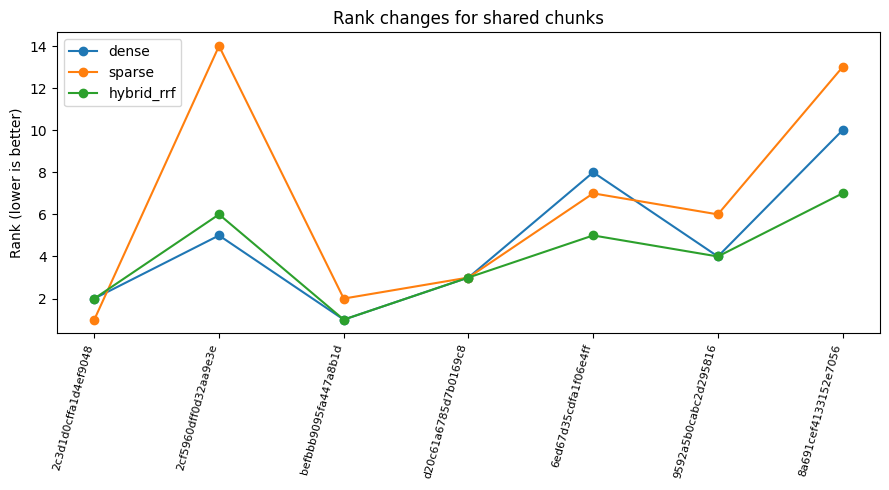

In [8]:
# ------------------------------------------------------------
# 6) Visualize ranking shifts across methods
# ------------------------------------------------------------
# We compare ranks of chunk IDs between dense, sparse, and fusion methods.

def build_rank_map(df, name):
    if df.empty:
        return {}
    return {cid: rank for cid, rank in zip(df['chunk_id'], df['rank'])}

rank_dense = build_rank_map(dense_df, 'dense')
rank_sparse = build_rank_map(sparse_df, 'sparse')
rank_rrf = build_rank_map(rrf_df, 'hybrid_rrf')

common_ids = list(set(rank_dense) & set(rank_sparse) & set(rank_rrf))[:20]
plot_rows = []
for cid in common_ids:
    plot_rows.append({
        'chunk_id': cid,
        'dense_rank': rank_dense[cid],
        'sparse_rank': rank_sparse[cid],
        'rrf_rank': rank_rrf[cid],
    })

rank_cmp = pd.DataFrame(plot_rows)
rank_cmp

if not rank_cmp.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    x = range(len(rank_cmp))
    ax.plot(x, rank_cmp['dense_rank'], marker='o', label='dense')
    ax.plot(x, rank_cmp['sparse_rank'], marker='o', label='sparse')
    ax.plot(x, rank_cmp['rrf_rank'], marker='o', label='hybrid_rrf')
    ax.set_xticks(list(x))
    ax.set_xticklabels(rank_cmp['chunk_id'], rotation=75, ha='right', fontsize=8)
    ax.set_ylabel('Rank (lower is better)')
    ax.set_title('Rank changes for shared chunks')
    ax.legend()
    plt.tight_layout()
    plt.show()

## Interpretation Notes

Use this walkthrough output to document:

- Which chunking setup preserves the most useful evidence boundaries.
- Where sparse retrieval adds exact-term matches that dense misses.
- How RRF changes top ranks by combining both signals.
- Whether rerank improves ordering quality for the sample query.